# Day 4 Roadmap
<table>
	<tr>
		<td style="width: 40%; vertical-align: top;">
			<img src="../Images/Seaborn_10.png" alt="Histogram" style="border-radius: 20px; width:
					100%;">
		</td>
		<td style="vertical-align: center; padding-left: 15px;">
			<h3>sns.histplot()</h3>
			<p>Understand frequency, bins, and the shape
				of a distribution.</p>
		</td>
	</tr>
	<tr>
		<td style="width: 40%; vertical-align: top;">
			<img src="../Images/Seaborn_11.png" alt="Density plot" style="border-radius: 20px; width:
					100%;">
		</td>
		<td style="vertical-align: center; padding-left: 15px;">
			<h3>sns.kdeplot()</h3>
			<p>Understand the smooth density curve of
				numerical data.</p>
		</td>
	</tr>
	<tr>
		<td style="width: 40%; vertical-align: top;">
			<img src="../Images/Seaborn_12.png" alt="Box plot" style="border-radius: 20px; width:
					100%;">
		</td>
		<td style="vertical-align: center; padding-left: 15px;">
			<h3>sns.displot()</h3>
			<p>Explore distributions and compare groups in
				separate panels.</p>
		</td>
	</tr>
</table>

# Imports and Dataset

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

df = sns.load_dataset("tips")

df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


# Part 1 — sns.histplot()
1. **Explanation**
A **histogram** shows how frequently numerical values fall within different ranges.

For example, using our familiar `tips` dataset:
- `total_bill` — how restaurant bills are distributed.
- `tip` — how tip amounts are distributed.
- `size` — how frequently different party sizes occur.

A histogram groups values into intervals called bins. The height of each bar represents the number of observations in that interval by default.

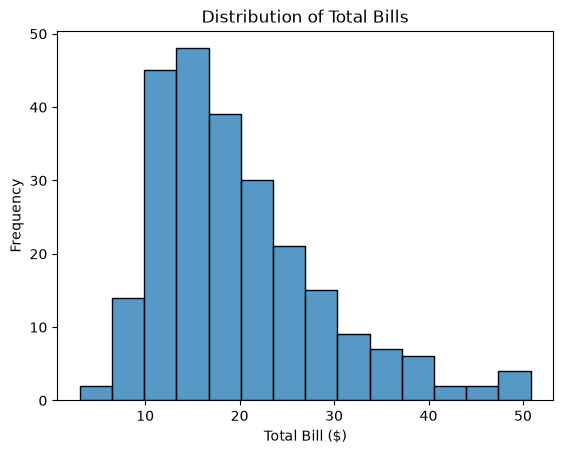

In [3]:
sns.histplot(data=df, x="total_bill")

plt.title("Distribution of Total Bills")
plt.xlabel("Total Bill ($)")
plt.ylabel("Frequency")

plt.show()

The height of each bar represents the number of customers whose total bills fall within that bill range.

**How to read the plot**
- **X-axis:** Total bill amount.
- **Y-axis:** Number of observations (customers) in each interval.
- **Bars:** Each bar represents a range of bill amounts.
- **Taller bar:** More customers have bills within that range.

## Understand bins
The bins parameter controls how many intervals the data is divided into.

<table>
	<tr>
		<td style="width: 40%; vertical-align: top;">
			<img src="../Images/Seaborn_13.png"
				alt="Histogram with fewer bins"
				style="border-radius: 20px; width:
					100%;">
		</td>
		<td style="width: 40%; vertical-align: top;">
			<img src="../Images/Seaborn_14.png"
				alt="Histogram with More bins"
				style="border-radius: 20px; width:
					100%;">
		</td>
	</tr>
	<tr>
		<td style="vertical-align: center; padding-left: 15px;">
			<h3>Fewer bins</h3>
			<p>Wider bars; the overall distribution is
				easier to see, but details may be
				hidden.</p>
		</td>
		<td style="vertical-align: center; padding-left: 15px;">
			<h3>More bins</h3>
			<p>Narrower bars; more detail, but the
				distribution may look noisier.</p>
		</td>
	</tr>
</table>

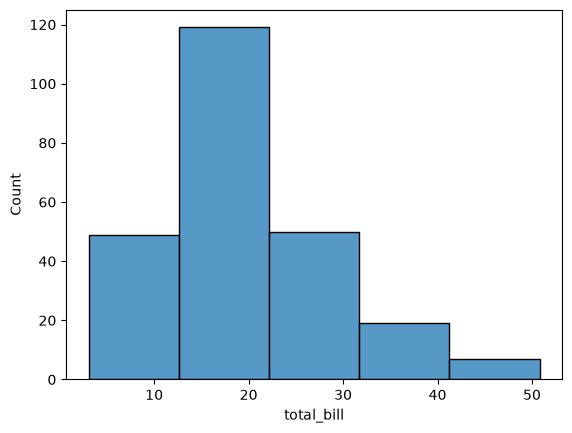

In [6]:
# Fewer bins
sns.histplot(
    data=df,
    x="total_bill",
    bins=5
)

plt.show()

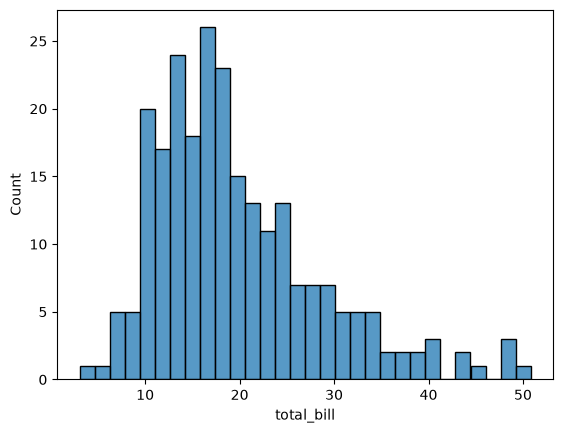

In [7]:
# More bins
sns.histplot(
    data=df,
    x="total_bill",
    bins=30
)

plt.show()

Notice how the same dataset can look different depending on the number of bins.

## kde argument
**Prediction:**\
What do you expect kde=True to do?

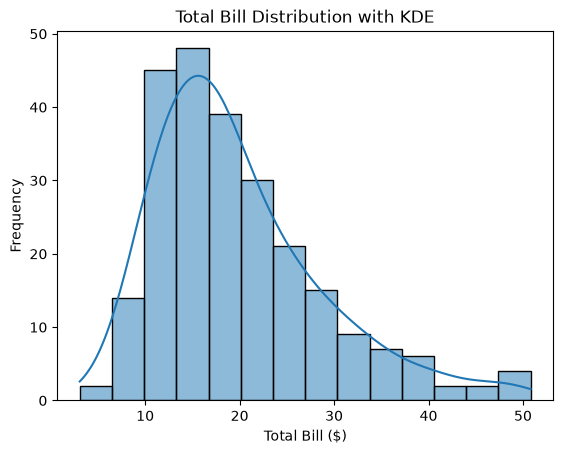

In [10]:
sns.histplot(data=df, x="total_bill", kde=True)

plt.title("Total Bill Distribution with KDE")
plt.xlabel("Total Bill ($)")
plt.ylabel("Frequency")
plt.show()

Setting `kde=True` adds a smooth density curve over the histogram bars, helping you understand the overall shape of the distribution.

**What you'll observe**
- Bars: Show the number of bills within each interval.
- Smooth curve: Shows the estimated density of bill amounts.
- Peaks in the curve: Indicate ranges where bill amounts are more concentrated.

One important detail: the histogram's y-axis shows **frequency**, while the KDE curve represents **probability density**. Their vertical scales are different, so don't interpret the curve's height as a customer count.

# Part 2 — sns.kdeplot()
You can plot the density curve by itself, without histogram bars.

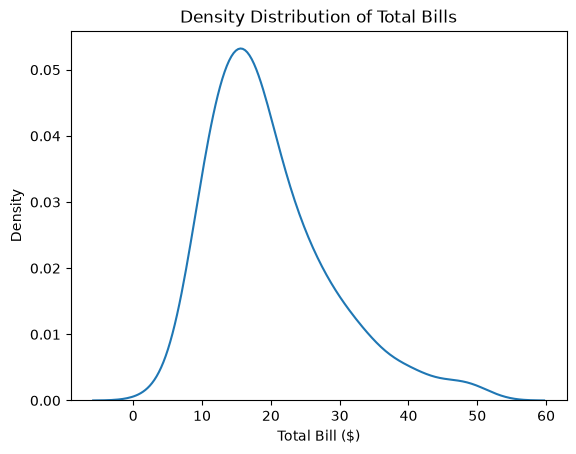

In [11]:
sns.kdeplot(data=df, x="total_bill")

plt.title("Density Distribution of Total Bills")
plt.xlabel("Total Bill ($)")
plt.ylabel("Density")

plt.show()

**Remember the difference:**
| Function | What it displays |
| :--- | :---|
| sns.histplot() | Frequency distribution using bars |
| sns.histplot(kde=True) | Histogram plus a smooth density curve |
| sns.kdeplot() | Smooth density curve only |

**Important:**\
The area under a properly normalized KDE curve represents **approximately 1**, or **100%** of the probability.

**Why is the area under a KDE curve equal to 1?**
A KDE (Kernel Density Estimate) curve represents the estimated distribution of numerical data. For a properly normalized density curve, the **total area under the curve equals 1.**

$$\int_{-\infty}^{\infty} f(x)\,dx=1$$

Think of 1 as representing **100% of the observations' probability.**
- A taller peak indicates that values are more concentrated around that range.
- A wider, flatter curve indicates that values are spread across a wider range.
- The area under a portion of the curve represents the estimated proportion of observations in that interval.

For example, if the area between two bill amounts is approximately **0.30**, that suggests roughly 30% of bills fall in that range, according to the estimated distribution.

## Compare two distributions
Let's use hue to compare total bills for smokers and non-smokers.

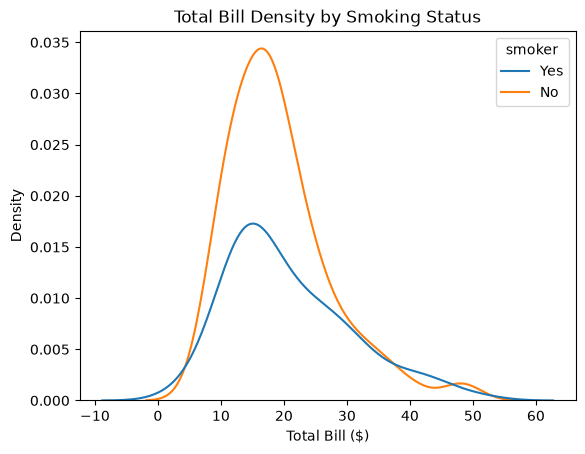

In [12]:
sns.kdeplot(
    data=df,
    x="total_bill",
    hue="smoker"
)

plt.title("Total Bill Density by Smoking Status")
plt.xlabel("Total Bill ($)")
plt.ylabel("Density")
plt.show()

This creates two density curves in the same plot, distinguished by color.

If the two curves overlap heavily then it would suggest that their total-bill distributions have some similarities, though they may still differ.

**Remember:** Overlap suggests similarity, not complete equality.

# Part 3 — sns.displot()
## Explanation
`sns.displot()` is a figure-level function that lets you visualize a variable's distribution and compare groups. It can create histograms or KDE plots.

You've already learned `histplot()` and `kdeplot()`. The new concept here is choosing the plot type with `kind` and splitting the data into panels.

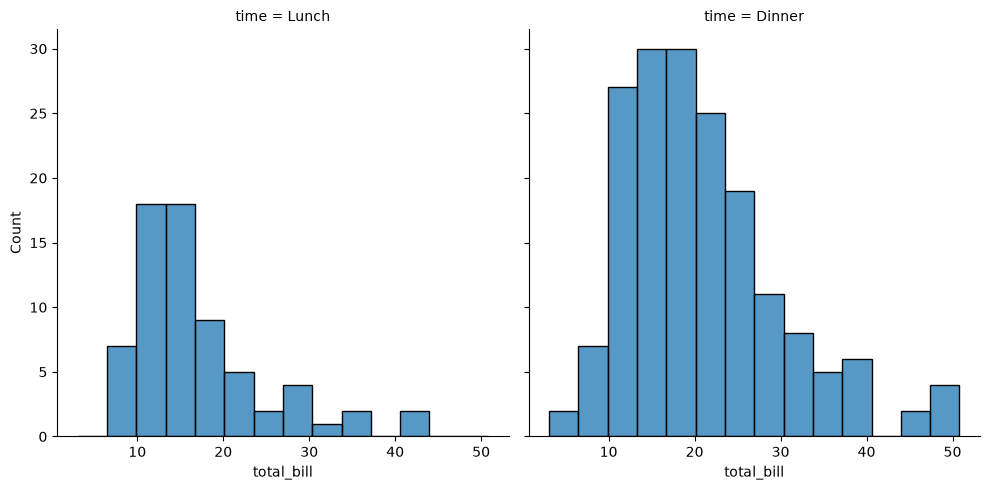

In [14]:
sns.displot(
    data=df,
    x="total_bill",
    kind="hist",
    col="time"
)

plt.show()

This produces two separate histograms, one for each meal time.
    
**Why?**
- kind="hist" creates histograms.
- col="time" creates separate panels for the two meal categories: Lunch and Dinner.
- x="total_bill" displays the distribution of bill amounts in each panel.

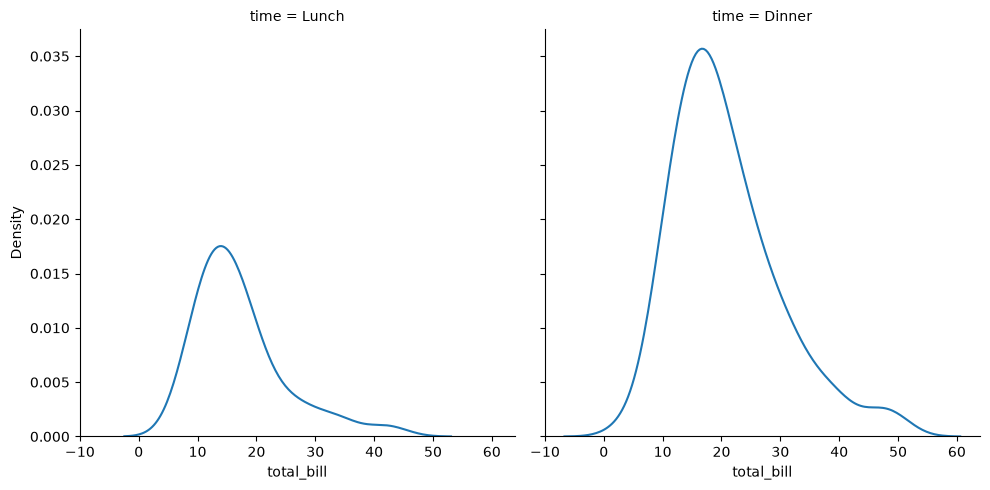

In [15]:
sns.displot(
    data=df,
    x="total_bill",
    kind="kde",
    col="time"
)

plt.show()

This produces two separate density curves, one for each meal time.

**Important distinction:** `displot()` is figure-level, while `histplot()` and `kdeplot()` are axes-level functions. That is why `displot()` conveniently supports `col` and `row` for faceted panels.

# Final Question for Day 4
What will this code create?
```python
sns.displot(
    data=df,
    x="total_bill",
    hue="smoker",
    col="time",
    kind="kde"
)

plt.show()
```
A. One histogram with four colors.

B. Two panels, each comparing smoker and non-smoker density curves.

C. Four separate panels, one for each smoking and meal-time combination.

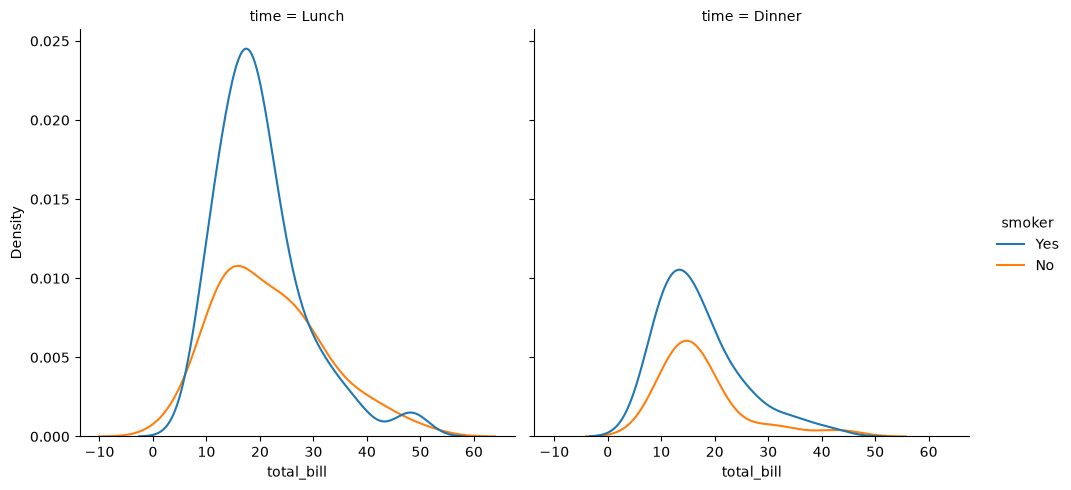

In [18]:
sns.displot(
    data=df,
    x="total_bill",
    hue="smoker",
    col="time",
    kind="kde"
)

plt.show()

**Answer:** `B. Two panels, each comparing smoker and non-smoker density curves.`

- `kind="kde"` creates density curves.
- `col="time"` creates two panels: Lunch and Dinner.
- `hue="smoker"` distinguishes smokers and non-smokers by color within each panel.

So you get two panels, each containing two group distributions.

# Revision notes
| Function | Purpose |
| :--- | :--- |
| sns.histplot() | Shows frequencies using histogram bars |
| sns.histplot(kde=True) | Histogram with a density curve |
| sns.kdeplot() | Shows an estimated density curve |
| sns.displot(kind="hist") | Creates a figure-level histogram |
| sns.displot(kind="kde") | Creates a figure-level KDE plot |

**Important parameters**
- `bins=20` — controls histogram binning.
- `kde=True` — adds a KDE curve to a histogram.
- `hue="smoker"` — distinguishes groups by color.
- `col="time"` — creates panels arranged in columns.
- `row="sex"` — creates panels arranged in rows.

# Mini-project: Tips distribution dashboard
Create a 2 × 2 dashboard to practice today's concepts.

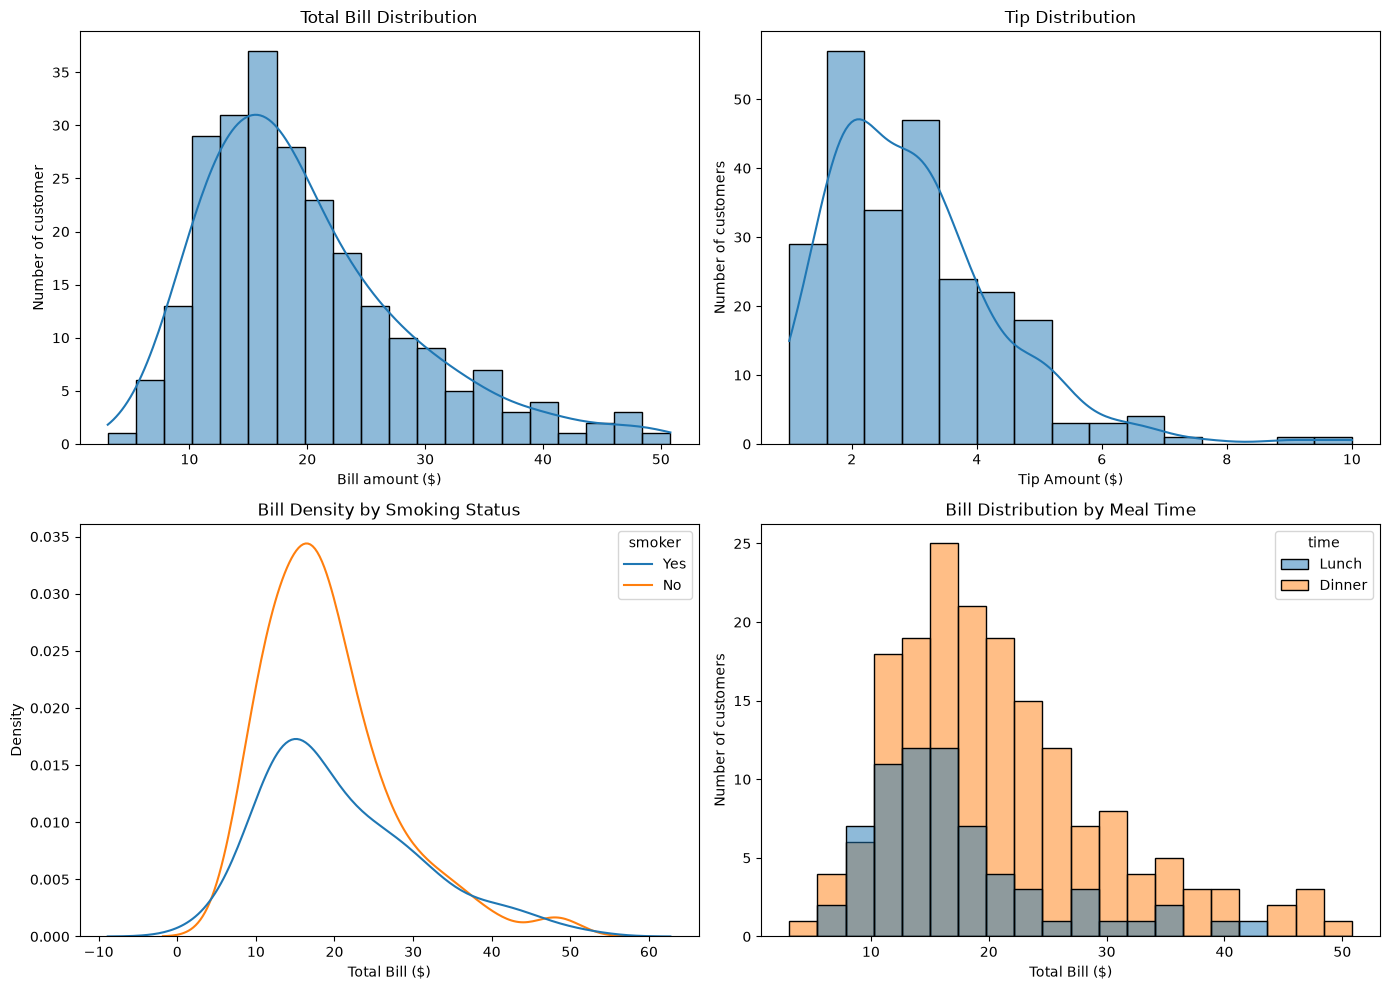

In [26]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(
    data=df,
    x="total_bill",
    bins=20,
    kde=True,
    ax=ax[0, 0]
)

ax[0, 0].set_title("Total Bill Distribution")
ax[0, 0].set_xlabel("Bill amount ($)")
ax[0, 0].set_ylabel("Number of customer")

sns.histplot(
    data=df,
    x="tip",
    bins=15,
    kde=True,
    ax=ax[0, 1]
)

ax[0, 1].set_title("Tip Distribution")
ax[0, 1].set_xlabel("Tip Amount ($)")
ax[0, 1].set_ylabel("Number of customers")

sns.kdeplot(
    data=df,
    x="total_bill",
    hue="smoker",
    ax=ax[1, 0]
)

ax[1, 0].set_title("Bill Density by Smoking Status")
ax[1, 0].set_xlabel("Total Bill ($)")
ax[1, 0].set_ylabel("Density")


sns.histplot(
    data=df,
    x="total_bill",
    hue="time",
    bins=20,
    ax=ax[1, 1]
)

ax[1, 1].set_title("Bill Distribution by Meal Time")
ax[1, 1].set_xlabel("Total Bill ($)")
ax[1, 1].set_ylabel("Number of customers")


plt.tight_layout()

plt.show()

## Observations
**Observation 1:** Most total bills appear concentrated around `$10–$20`.

**Observation 2:** Tip amounts appear concentrated around approximately `$2`.

**Observation 3:** The KDE curves show how the total-bill distributions differ between smokers and non-smokers; group averages should be checked separately.

**Observation:** The dinner and lunch histograms show how bill amounts are distributed by meal time; compare total counts separately to determine which meal has more customers.